# Predict wine quality score (on a scale)

Success Criteria
Achieve RMSE lower than baseline (e.g., mean predictor), plus R² > 0.4 (or higher) and identify key features influencing quality.

In [ ]:
import pandas as pd

In [ ]:
# Load datasets
red = pd.read_csv('winequality-red.csv', sep=';')
white = pd.read_csv('winequality-white.csv', sep=';')


In [ ]:
# Add type column
red['type'] = 1
white['type'] = 0

In [ ]:
# Combine
wine = pd.concat([red, white], axis=0)

In [ ]:
# Check for missing values (there shouldn't be any)
print(wine.isnull().sum())


fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
type                    0
dtype: int64


In [ ]:
# Basic stats
print(wine.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    6497.000000       6497.000000  6497.000000     6497.000000   
mean        7.215307          0.339666     0.318633        5.443235   
std         1.296434          0.164636     0.145318        4.757804   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.400000          0.230000     0.250000        1.800000   
50%         7.000000          0.290000     0.310000        3.000000   
75%         7.700000          0.400000     0.390000        8.100000   
max        15.900000          1.580000     1.660000       65.800000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  6497.000000          6497.000000           6497.000000  6497.000000   
mean      0.056034            30.525319            115.744574     0.994697   
std       0.035034            17.749400             56.521855     0.002999   
min       0.009000             1.000000         

In [ ]:
# Save combined if needed
wine.to_csv('winequality-combined.csv', index=False)

The features are: fixed acidity, volatile acidity, citric acid, residual sugar, chlorides, free sulfur dioxide, total sulfur dioxide, density, pH, sulphates, alcohol, type. Target: quality.

# Exploratory Data Analysis (EDA)
Visualize and understand the data to spot patterns.

Check distribution of quality scores.
Correlation heatmap to see feature relationships.
Boxplots for features vs. quality.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns


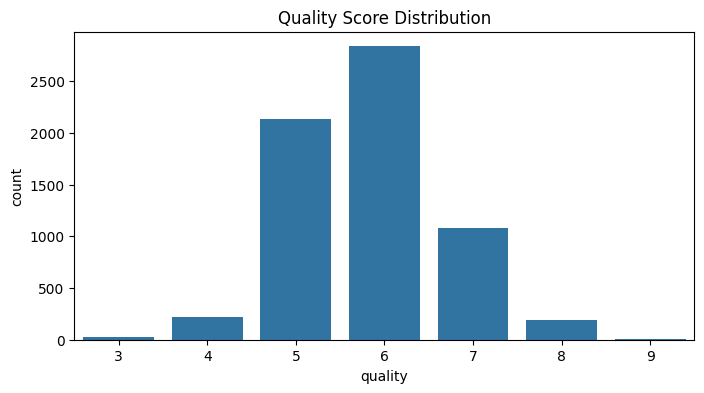

In [ ]:
# Quality distribution
plt.figure(figsize=(8, 4))
sns.countplot(x='quality', data=wine)
plt.title('Quality Score Distribution')
plt.show()

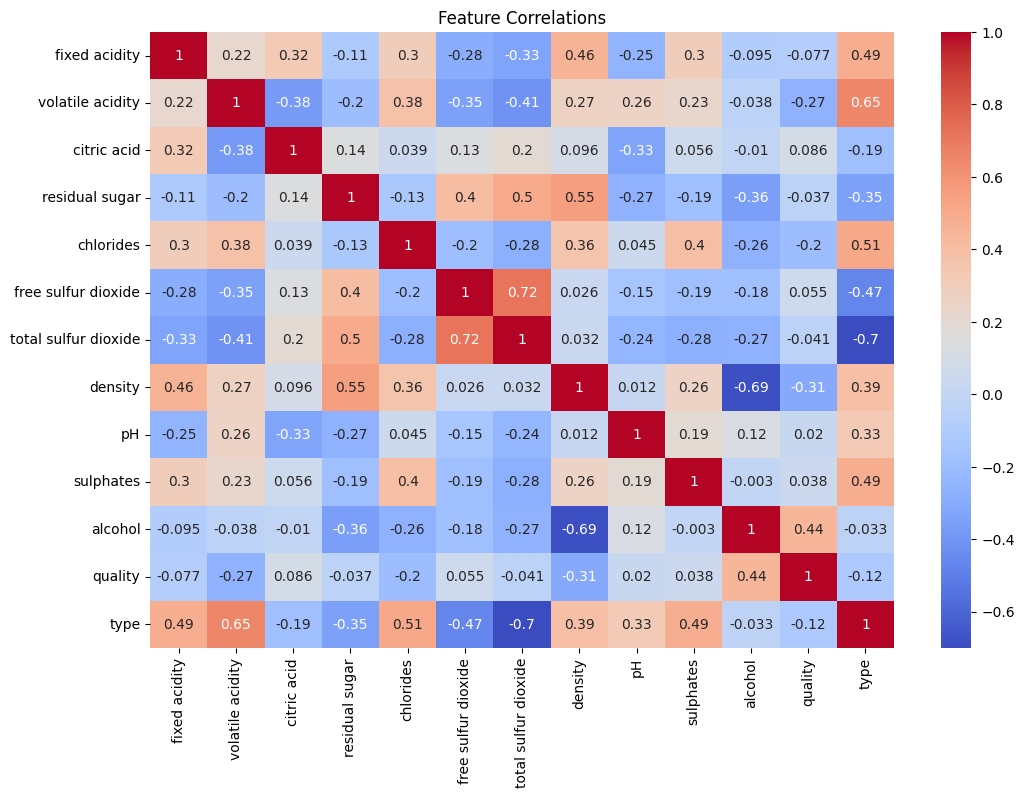

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(wine.corr(), annot=True, cmap='coolwarm')
plt.title('Feature Correlations')
plt.show()

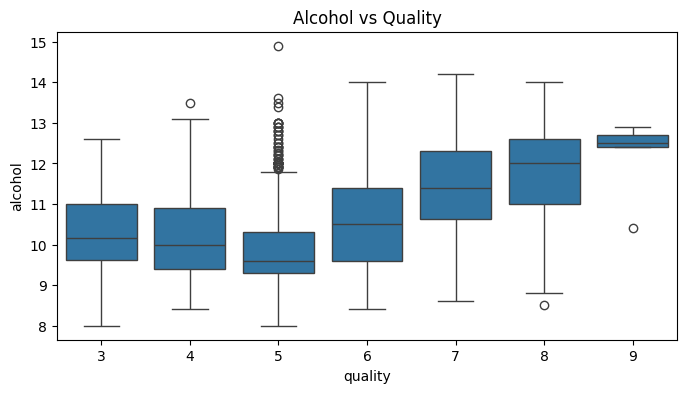

In [ ]:
# Example boxplot for alcohol vs quality
plt.figure(figsize=(8, 4))
sns.boxplot(x='quality', y='alcohol', data=wine)
plt.title('Alcohol vs Quality')
plt.show()

From EDA, you'll see alcohol positively correlates with quality, volatile acidity negatively, etc. Quality is imbalanced (mostly 5-7), so consider that in modeling.

# Preprocess the Data

Split into features (X) and target (y).
Train-test split (80/20).
Scale features (important for some models like SVR, but optional for tree-based like Random Forest).

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
X = wine.drop('quality', axis=1)
y = wine['quality']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Optional scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Establish Baseline
The baseline is predicting the mean quality for all samples. Calculate its RMSE.

In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

baseline_pred = np.full_like(y_test, y_train.mean())
baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred)) #You take the square root of the MSE to get the RMSE
print(f'Baseline RMSE: {baseline_rmse:.3f}')

Baseline RMSE: 1.197


# Train and Evaluate Models
Start with simple models, then move to better ones like Random Forest.

Linear Regression (baseline model).
Support Vector Regression (SVR).
Random Forest (ensemble, often best here).

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)  # No scaling needed
lr_pred = lr.predict(X_test)
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))
lr_r2 = r2_score(y_test, lr_pred)
print(f'Linear Regression - RMSE: {lr_rmse:.3f}, R²: {lr_r2:.3f}')


Linear Regression - RMSE: 0.736, R²: 0.267


In [ ]:
# SVR (use scaled data)
svr = SVR()
svr.fit(X_train_scaled, y_train)
svr_pred = svr.predict(X_test_scaled)
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_pred))
svr_r2 = r2_score(y_test, svr_pred)
print(f'SVR - RMSE: {svr_rmse:.3f}, R²: {svr_r2:.3f}')

SVR - RMSE: 0.675, R²: 0.383


In [ ]:
# Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)  # No scaling needed
rf_pred = rf.predict(X_test)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)
print(f'Random Forest - RMSE: {rf_rmse:.3f}, R²: {rf_r2:.3f}')

Random Forest - RMSE: 0.608, R²: 0.499


Identify Key Features
Use feature importance from Random Forest.

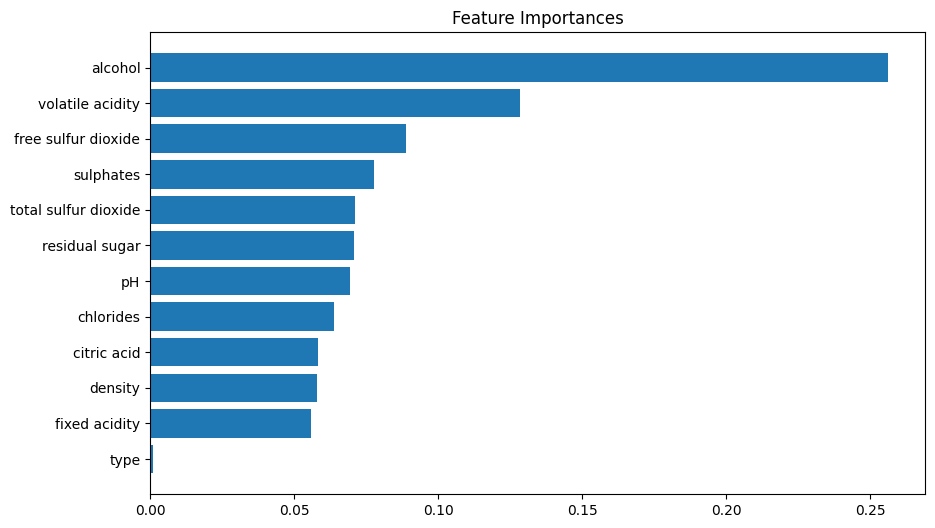

In [ ]:
importances = best_rf.feature_importances_
features = X.columns
sorted_idx = importances.argsort()

plt.figure(figsize=(10, 6))
plt.barh(features[sorted_idx], importances[sorted_idx])
plt.title('Feature Importances')
plt.show()

Top features: alcohol (~0.25 importance), volatile acidity (~0.13), sulphates/free SO2 (~0.09-0.12). Interpret: Higher alcohol boosts quality; lower volatile acidity avoids off-tastes.

Include EDA visuals, model comparisons in a table, feature importances.

In [ ]:
results = pd.DataFrame({
    'Model': ['Baseline', 'Linear', 'SVR', 'Random Forest'],
    'RMSE': [baseline_rmse, lr_rmse, svr_rmse, rf_rmse],
    'R²': [0, lr_r2, svr_r2, rf_r2]
})
print(results)


           Model      RMSE        R²
0       Baseline  1.197433  0.000000
1         Linear  0.735689  0.267157
2            SVR  0.675176  0.382757
3  Random Forest  0.608104  0.499299


Baseline Beaten: Your baseline model had an RMSE of 1.197. All three of your machine learning models (Linear, SVR, and Random Forest) easily beat this, proving their predictive value.

Success Criteria Met: Your goal was to achieve an R² > 0.4.

Linear Regression (0.267) and SVR (0.383) failed to meet this target.

The Random Forest model (0.499) succeeded, explaining just under 50% of the variance in wine quality.

